# 19 — How our Most Improved predictor evolved

**In brief**
- **Question:** How did the Most Improved predictor get from a first idea to today's model, and what did each decision add?
- **Answer:** From "the biggest points jump" to the current model, tested the same way at every stage. At season's end the model went from 11.4 to 24.9 times a blind guess, and from the winner in our top 7 in 11 of 21 seasons to 17. The biggest gain came from understanding voters.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D22, D24, D26, D27, D29, D38, D39.
- **Where it fits:** The best single place to see how the Most Improved model was built.
- **Dated:** findings written 10 November 2026; numbers checked against the outputs on 10 November 2026.

**In detail.** We did not arrive at the current Most Improved Player (MIP) model in one step. It was built through a series of decisions, each made because something was wrong or missing. This notebook rebuilds the predictor **one decision at a time**, from the simplest possible starting point to the model in use today, and measures what each step bought.

**One test bed for every stage**, so the steps can be compared fairly:
- **The in-season predictor** (the live race, notebook 12) is scored on every season from 2000-01 to 2025-26, at three points of each season: **day 19** (where the live race is now), **day 85** (mid-January) and **the end of the season**.
- **The preseason predictor** (notebook 11) is scored on the 14 preseasons from 2012-13 to 2025-26.
- **Two tests for each:**
  - **Strict:** each season is predicted only from earlier seasons, exactly as it could have been at the time.
  - **Leave-one-out:** each season is predicted from all the others.

**Measures:**
- How often the eventual winner is our #1, in our top 3 and in our top 7.
- His median rank.
- **"× a blind guess":** how much more likely, on average, the model thought the actual winner was than a random pick from the candidates. 1× is no better than chance.

Award votes are used only to mark the predictions. The penalty λ = 3 (D30) and the scoring turning point at 20 points (D27; the live race now chooses it each day, D32, and it has always chosen 20) are held fixed so that only the inputs change.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs
from unicorn.hot_start import add_stale
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, apply_style
from unicorn.preseason import (LAST_SEASON_LEAN, MOMENTUM, PRE_FORM_LEAN, PROFILE, TURN, TEAM_CHANGE, ESTABLISHED, RETURNING,
                               add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame)
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
L2 = MH.L2
sel = load_selections()
games = MH.load_games()                                   # baseline = most recent season with 33%+ of the games (D22)
info = MH.player_info()
votes, winners = MH.voting(games)
# the same game logs with the ORIGINAL baseline: simply the previous season, however few games (before D22)
games0, _, _ = build_game_table(load_game_logs(MH.OLD_SEASONS + GAMELOG_SEASONS), baseline_min_share=0.0)
games0["day"] = (games0["game_date"] - games0.groupby("season")["game_date"].transform("min")).dt.days

POINTS = {"day 19": 19, "day 85 (mid-January)": 85, "end of season": None}
from unicorn.mip_eval import current_frame, scorecard, winner_ranks
def frame(g, day):
    return current_frame(g, info, winners, sel, day=day)          # the live race's inputs, turning point at 20
frames = {(k, base): frame(g, d) for k, d in POINTS.items() for base, g in [("previous season", games0), ("33%+ season", games)]}
print({k: len(v) for k, v in frames.items()})

{('day 19', 'previous season'): 7265, ('day 19', '33%+ season'): 7057, ('day 85 (mid-January)', 'previous season'): 7548, ('day 85 (mid-January)', '33%+ season'): 7331, ('end of season', 'previous season'): 7756, ('end of season', '33%+ season'): 7509}


In [2]:
def score(f, feats=None, scheme="strict", rule=None):
    """Rank of the eventual winner each season; feats = a choice model, rule = rank by one column (no model)."""
    return scorecard(winner_ranks(f, feats, L2, scheme, rule=rule))

DX = GAMELOG_DELTAS + GAMELOG_DEFENSE
STAGES = [  # (stage, decision, baseline, inputs or rule, what changed)
    ("0. Biggest points jump", "starting point", "previous season", "ppg_delta", "Rank players by how much their scoring rose. No model."),
    ("1. Choice model, box-score changes", "D24", "previous season", DX, "One winner per season; every box-score change, weighted by a model."),
    ("2. Skip injury-shortened baselines", "D22", "33%+ season", DX, "Compare with the last season of 33%+ of games, so a comeback is not a leap."),
    ("3. + relative change, team, age, second year", "D24", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR, "How voters really judge: relative jumps, winning, youth, no second-year winners."),
    ("4. + scoring turning point at 20", "D27", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn"], "Scoring helps up to 20 points a game, then counts against (MVP material, not MIP)."),
    ("5. + already an All-Star", "D38", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn", "prior_allstar"], "Voters pass over established stars: 0 of 26 winners."),
    ("6. + back from a lost season", "D39", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn", "prior_allstar", "stale"], "A comeback is a return, not an improvement: 0 of 26 winners."),
]
rows = []
for stage, dec, base, feats, _ in STAGES:
    for point in POINTS:
        f = frames[(point, base)]
        for scheme in ["strict", "leave-one-out"]:
            s = score(f, rule=feats, scheme=scheme) if isinstance(feats, str) else score(f, feats, "loso" if scheme == "leave-one-out" else "strict")
            rows.append({"stage": stage, "decision": dec, "point": point, "test": scheme, **s})
inseason = pd.DataFrame(rows)
inseason.pivot_table(index=["stage"], columns=["point", "test"], values="× a blind guess", sort=False).round(1)

point                                        day 19                \
test                                         strict leave-one-out   
stage                                                               
1. Choice model, box-score changes              3.6           4.2   
2. Skip injury-shortened baselines              4.0           4.7   
3. + relative change, team, age, second year    5.1           6.4   
4. + scoring turning point at 20                6.0           7.4   
5. + already an All-Star                        6.4           7.9   
6. + back from a lost season                    6.5           8.1   

point                                        day 85 (mid-January)  \
test                                                       strict   
stage                                                               
1. Choice model, box-score changes                           10.2   
2. Skip injury-shortened baselines                           12.0   
3. + relative change, team, age, second year                 16.1   
4. + scoring turning point at 20                             18.5   
5. + already an All-Star                                     19.8   
6. + back from a lost season                                 19.9   

point                                                      end of season  \
test                                         leave-one-out        strict   
stage                                                                      
1. Choice model, box-score changes                    14.0          11.4   
2. Skip injury-shortened baselines                    16.0          13.7   
3. + relative change, team, age, second year          22.0          19.2   
4. + scoring turning point at 20                      23.9          23.0   
5. + already an All-Star                              25.5          24.6   
6. + back from a lost season                          25.7          24.9   

point                                                       
test                                         leave-one-out  
stage                                                       
1. Choice model, box-score changes                    16.9  
2. Skip injury-shortened baselines                    20.0  
3. + relative change, team, age, second year          28.3  
4. + scoring turning point at 20                      32.4  
5. + already an All-Star                              34.6  
6. + back from a lost season                          35.0

In [3]:
# the strict test in full, at each point of the season
for point in POINTS:
    print(f"STRICT TEST, {point.upper()} ({int(inseason.loc[(inseason['point'] == point) & (inseason['test'] == 'strict'), 'seasons'].iloc[0])} seasons)")
    display(inseason[(inseason["point"] == point) & (inseason["test"] == "strict")].set_index("stage")[["decision", "winner #1", "in top 3", "in top 7", "median rank", "× a blind guess"]]
            .style.format({"median rank": "{:.1f}", "× a blind guess": "{:.1f}"}, na_rep="–"))

STRICT TEST, DAY 19 (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,0,2,6,11.0,–
"1. Choice model, box-score changes",D24,2,5,8,17.0,3.6
2. Skip injury-shortened baselines,D22,1,5,9,16.0,4.0
"3. + relative change, team, age, second year",D24,1,5,10,9.0,5.1
4. + scoring turning point at 20,D27,3,8,11,5.0,6.0
5. + already an All-Star,D38,3,7,11,5.0,6.4
6. + back from a lost season,D39,3,7,11,5.0,6.5


STRICT TEST, DAY 85 (MID-JANUARY) (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,3,5,12,6.0,–
"1. Choice model, box-score changes",D24,2,8,13,6.0,10.2
2. Skip injury-shortened baselines,D22,2,9,13,4.0,12.0
"3. + relative change, team, age, second year",D24,5,11,16,3.0,16.1
4. + scoring turning point at 20,D27,4,10,16,4.0,18.5
5. + already an All-Star,D38,4,10,17,4.0,19.8
6. + back from a lost season,D39,4,10,17,4.0,19.9


STRICT TEST, END OF SEASON (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,2,7,11,7.0,–
"1. Choice model, box-score changes",D24,4,7,13,5.0,11.4
2. Skip injury-shortened baselines,D22,6,10,13,5.0,13.7
"3. + relative change, team, age, second year",D24,7,12,15,2.0,19.2
4. + scoring turning point at 20,D27,7,12,17,2.0,23.0
5. + already an All-Star,D38,7,12,17,2.0,24.6
6. + back from a lost season,D39,7,12,17,2.0,24.9


## The preseason predictor

Built in notebook 11, before a game has been played, from last season and the preseason. Its stages:

In [4]:
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_stale(add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel))
FH = F[F["season"] != "2026-27"].reset_index(drop=True)
PRE_STAGES = [
    ("0. Best last season", "starting point", ["mpg_last", "ppg_last"], "Last season's minutes and points only."),
    ("1. + profile (age, second year, team)", "D24", LAST_SEASON_LEAN + PROFILE, "The same voter preferences as in-season: age, second year, team success."),
    ("2. + last season's trend", "–", LAST_SEASON_LEAN + PROFILE + MOMENTUM, "Players already improving, and strong finishers."),
    ("3. + preseason form per 36", "D26", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN, "Preseason rates, never totals, shrunk for small samples."),
    ("4. + scoring turning point at 20", "D27", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN, "Established scorers handled by a turning point, not excluded."),
    ("5. + a 20-point scorer left", "D29", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE, "An open role: the strongest preseason clue."),
    ("6. + already an All-Star", "D38", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE + ESTABLISHED, "Voters pass over established stars."),
    ("7. + back from a lost season", "D39", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE + ESTABLISHED + RETURNING, "A comeback is a return, not an improvement."),
]
prows = []
for stage, dec, feats, _ in PRE_STAGES:
    for scheme in ["strict", "leave-one-out"]:
        prows.append({"stage": stage, "decision": dec, "test": scheme, **score(FH, feats, "loso" if scheme == "leave-one-out" else "strict")})
preseason = pd.DataFrame(prows)
preseason.pivot_table(index="stage", columns="test", values=["in top 7", "median rank", "× a blind guess"], sort=False).round(1)

in top 7               median rank  \
test                                    strict leave-one-out      strict   
stage                                                                      
0. Best last season                        0.0           1.0        50.0   
1. + profile (age, second year, team)      0.0           3.0        79.0   
2. + last season's trend                   2.0           3.0        44.0   
3. + preseason form per 36                 2.0           4.0        16.0   
4. + scoring turning point at 20           1.0           3.0        14.0   
5. + a 20-point scorer left                4.0           7.0        15.0   
6. + already an All-Star                   5.0           8.0         7.0   
7. + back from a lost season               5.0           9.0         7.0   

                                                    × a blind guess  \
test                                  leave-one-out          strict   
stage                                                                 
0. Best last season                            51.0             1.4   
1. + profile (age, second year, team)          44.0             1.7   
2. + last season's trend                       39.5             1.8   
3. + preseason form per 36                     14.5             2.9   
4. + scoring turning point at 20               11.5             3.3   
5. + a 20-point scorer left                     7.0             4.9   
6. + already an All-Star                        6.0             5.6   
7. + back from a lost season                    6.0             6.0   

                                                     
test                                  leave-one-out  
stage                                                
0. Best last season                             1.4  
1. + profile (age, second year, team)           1.8  
2. + last season's trend                        2.6  
3. + preseason form per 36                      5.1  
4. + scoring turning point at 20                5.6  
5. + a 20-point scorer left                     7.1  
6. + already an All-Star                        8.2  
7. + back from a lost season                    8.9

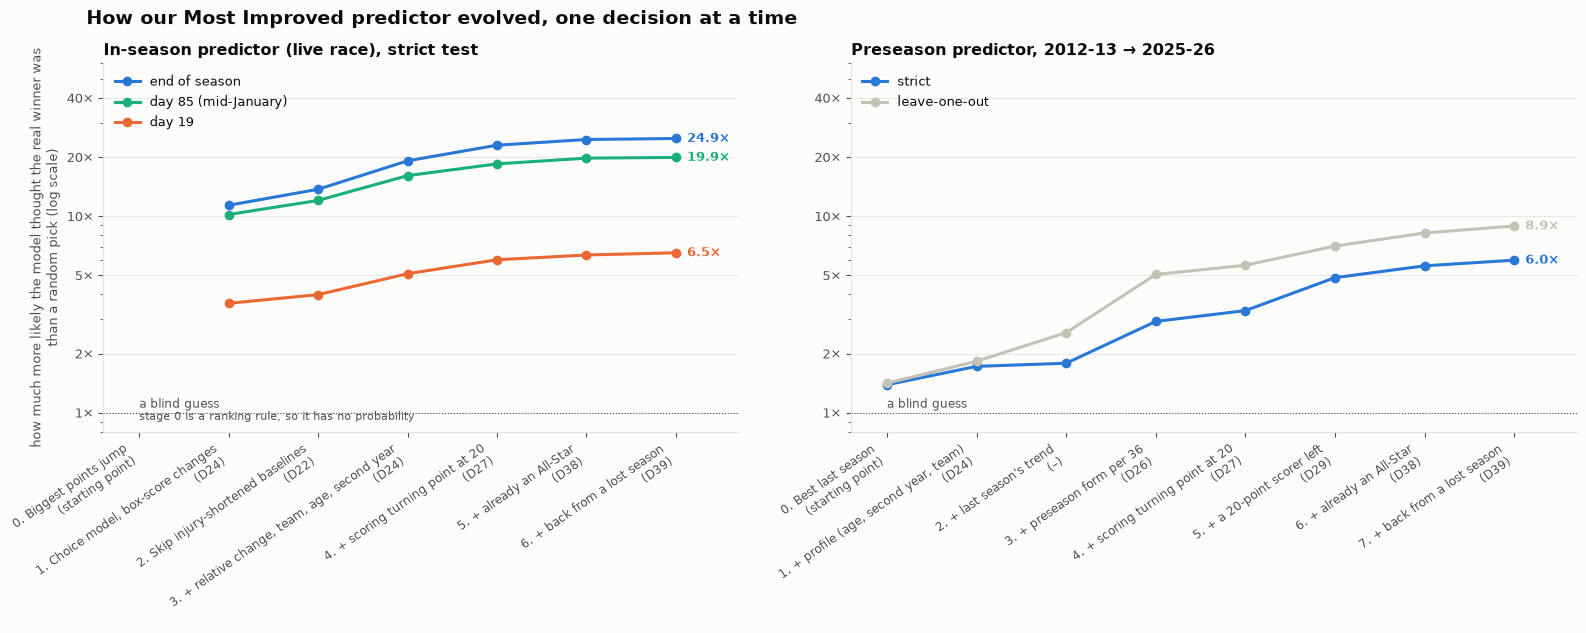

In [5]:
# chart: what each decision bought, as "× better than a blind guess" (strict test)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={"width_ratios": [7, 8]})
for ax, data, stages, lines, title in [
        (a1, inseason, STAGES, [("end of season", "strict", BLUE), ("day 85 (mid-January)", "strict", SERIES[2]), ("day 19", "strict", ORANGE)], "In-season predictor (live race), strict test"),
        (a2, preseason, PRE_STAGES, [(None, "strict", BLUE), (None, "leave-one-out", MUTED)], "Preseason predictor, 2012-13 → 2025-26")]:
    names = [s[0] for s in stages]
    x = np.arange(len(names))
    for point, scheme, col in lines:
        d = data[(data["test"] == scheme) & ((data["point"] == point) if point else True)].set_index("stage").reindex(names)
        y = d["× a blind guess"].to_numpy()
        lab = f"{point}" if point else scheme
        ax.plot(x, y, marker="o", color=col, linewidth=2.2, label=lab)
        last = np.where(~np.isnan(y))[0][-1]
        ax.annotate(f"{y[last]:.1f}×", (x[last], y[last]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5, color=col, fontweight="bold")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}×"); ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks([1, 2, 5, 10, 20, 40]); ax.set_ylim(0.8, 60)
    ax.axhline(1, color=INK2, linewidth=0.8, linestyle=":"); ax.text(0, 1.06, "a blind guess", fontsize=8.5, color=INK2)
    ax.set_xticks(x, [f"{s[0]}\n({s[1]})" for s in stages], rotation=35, ha="right", fontsize=8.5)
    ax.set_xlim(-0.4, len(names) - 0.3); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=11.5); ax.legend(frameon=False, loc="upper left", fontsize=9)
a1.set_ylabel("how much more likely the model thought the real winner was\nthan a random pick (log scale)")
a1.text(0, 0.92, "stage 0 is a ranking rule, so it has no probability", fontsize=8, color=INK2)
fig.suptitle("How our Most Improved predictor evolved, one decision at a time", x=0.06, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "19_predictor_evolution.png", dpi=150, bbox_inches="tight")

## 19 findings: how we got here

**The in-season predictor (the live race), strict test, 21 seasons:**

| Stage | Decision | Why we made it | End of season: winner #1 / top 7 / × blind | Day 19: top 7 / median rank / × blind |
|---|---|---|---|---|
| 0. Biggest points jump | starting point | The obvious first idea: the player whose scoring rose most | 2 / 11 / – | 6 / 11 / – |
| 1. Choice model on box-score changes | D24 | One winner per season; every statistic, weighted by what voters actually rewarded | 4 / 13 / 11.4× | 8 / 17 / 3.6× |
| 2. Skip injury-shortened baselines | D22 | Kawhi Leonard's and Derrick Rose's comebacks looked like leaps against a 9- or 25-game season | 6 / 13 / 13.7× | 9 / 16 / 4.0× |
| 3. + relative change, team, age, second year | D24 | Voters reward a jump that is large *for that player*, winning teams and youth, and rarely pick second-year players (the last was Monta Ellis in 2006-07) | 7 / 15 / 19.2× | 10 / 9 / 5.1× |
| 4. + scoring turning point at 20 | D27 | Established scorers are MVP material, not MIP; no winner had scored more than 20.3 the season before | 7 / 17 / 23.0× | 11 / 5 / 6.0× |
| 5. + already an All-Star | D38 | 0 of 26 winners had been an All-Star; the live board had Sengun at #2 | 7 / 17 / 24.6× | 11 / 5 / 6.4× |
| 6. + back from a lost season | D39 | 0 of 26 winners were coming back from a lost season; Ty Jerome's 26% lead | 7 / 17 / **24.9×** | 11 / 5 / **6.5×** |

**What the journey shows:**
- **The model roughly doubled its sharpness, at every point of the season.** At season's end it went from 11.4× to 24.9× a blind guess, and the winner moved from top 7 in 11 seasons to 17. At day 19 it went from 3.6× to 6.5×, and the median winner rank from 11 to 5.
- **The biggest single gain came from understanding voters** (stage 3: relative change, team, age, second year), then from the baseline fix (stage 2) and the turning point (stage 4).
- **The latest steps are smaller, as expected.** The All-Star input adds about 7%, and the lost-season input about 1–2%. Each was kept because it helped in every test, not because it helped a lot. They matter most for the *shape* of the top of the list: removing established stars and comebacks voters were never going to pick.
- **The order of the top changes more than the fit.** Winner #1 at season's end went from 2 seasons (the simple rule) to 7. The last three steps left that unchanged and improved the ranks just below the top.

**The preseason predictor, 2012-13 → 2025-26** (strict, 9 seasons / leave-one-out, 14):

| Stage | Decision | Winner in our top 7 | Median rank | × blind (strict) |
|---|---|---|---|---|
| 0. Best last season | starting point | 0 / 1 | 50 | 1.4× |
| 1. + profile (age, second year, team) | D24 | 0 / 3 | 79 / 44 | 1.7× |
| 2. + last season's trend | – | 2 / 3 | 44 / 39.5 | 1.8× |
| 3. + preseason form per 36 | D26 | 2 / 4 | 16 / 14.5 | 2.9× |
| 4. + scoring turning point at 20 | D27 | 1 / 3 | 14 / 11.5 | 3.3× |
| 5. + a 20-point scorer left | D29 | 4 / 7 | 15 / 7 | 4.9× |
| 6. + already an All-Star | D38 | 5 / 8 | 7 / 6 | 5.6× |
| 7. + back from a lost season | D39 | 5 / 9 | 7 / 6 | **6.0×** |

- **Before the season, the two big gains were preseason form** (D26: 1.8× → 2.9×) **and an open role** (D29: 3.3× → 4.9×, the winner in the top 7 in 7 of 14 seasons instead of 3).
- **From last season alone, the winner was almost invisible** (median rank 50). With everything known on opening night, his median rank is 7.

**What was left open, and has since been checked:** the early-season leaders looked too sure of themselves. Notebook 20 tested this: the chances are honest almost everywhere, but big early favourites win less often than their chances say, so the live race flags them instead of correcting them (D40).
